# Distributed Quantum Reservoir Computing — a reproduction, a fair test, and a photonic adaptation

**Paper:** Liliopoulos *et al.*, *Scalable Quantum Reservoir Computing over Distributed Quantum Architectures*, arXiv:2605.04991 (2026).

This notebook is the entry point to the reproduction in `papers/distributed_qrc/`. It does not just replay the paper's numbers. It makes a **scientific argument**:

1. What does the paper claim, and what evidence would weaken that claim?
2. Do we obtain the paper's numbers when we rebuild its models?
3. Do the numbers still support the claim once the models face **fair classical competitors** and **controls** that test alternative explanations?
4. What happens when the method is translated to **linear-optical (photonic) hardware** with MerLin?

**How to read it.**
- *Live cells* recompute small things in under a few minutes on a laptop CPU: data checks, known-answer tests, and a reduced run of one architecture.
- *Stored-evidence cells* load the full 3-seed results from `results/`. Those results come from the logged and audited sweeps described in `LOG.md`.

Each stored-evidence section names its source.

| Scope label | Meaning in this notebook |
|---|---|
| **reproduction** | the paper's models and protocol rebuilt from the text |
| **control** | an experiment designed to separate the paper's explanation from an alternative |
| **robustness** | the same comparison under changed but defensible choices |
| **extension** | something the paper does not do (the MerLin photonic adaptation) |

## 1. Problem statement and the paper's claim

**Task.** One-step-ahead forecasting of the Greek national electricity load: from the last 4 hourly values, predict the next hour.

**Model family.** Reservoir computing: a fixed (untrained) nonlinear *reservoir* turns the input window into features, and only a ridge-regression *readout* is trained. The paper makes both parts quantum:

| Component | Classical version | "Quantum" version in the paper |
|---|---|---|
| Reservoir | ReservoirPy echo-state network | a network of N 4-qubit "quantum neurons" (Fig. 2) |
| Readout | linear ridge regression | kernel ridge with a *fidelity kernel* $K(x,x') = \lvert\langle\phi(x)\vert\phi(x')\rangle\rvert^2$ ("quantum ridge", Fig. 3) |

There are four **architectures**: one or several reservoirs (SR/MR), feeding one or several readouts (SR/MR):

| Architecture | Reservoirs | Readouts |
|---|---|---|
| SRSR | 1 | 1 |
| MRSR | k, features concatenated | 1 |
| SRMR | 1 | m, each on a feature chunk |
| MRMR | k | k, reservoir i → readout i |

The readout predictions are averaged.

**Central claim (C1), to be falsified.** Quantum-enhanced variants beat the architecture-matched classical baseline, with average MAE reductions of 28.5 % (SRSR), 25.6 % (MRSR), 54.2 % (SRMR) and 52.1 % (MRMR), and a peak of −78.8 %.

**Secondary claims:**
- **C2:** the quantum-kernel readout is the main contributor.
- **C3:** distributed architectures match or beat single-node ones.
- **C4:** fully quantum models are more stable than hybrids for small reservoirs.
- **C5:** the gains persist under hardware noise.
- **C6:** distribution mitigates noise.
- **C7:** the best model is a 3×20 classical reservoir with a quantum kernel (MAE 0.0113).

**What would weaken C1:**
- (a) a classical model with the *same inputs and readout type* that matches the quantum models;
- (b) the gain disappearing when the best cell is chosen on validation data instead of test data;
- (c) the gain being explained by a weak or unstable baseline rather than by the quantum components.

In [1]:
import copy, json, sys, tempfile, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

warnings.filterwarnings("ignore")

# Locate the paper folder (this notebook lives in papers/distributed_qrc/).
PAPER_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lib" / "runner.py").exists() and p.name == "distributed_qrc")
REPO_ROOT = PAPER_DIR.parents[1]
for path in (str(REPO_ROOT), str(PAPER_DIR.parent)):
    if path not in sys.path:
        sys.path.insert(0, path)

from runtime_lib.config import deep_update, load_config
from runtime_lib.dtypes import resolve_config_dtypes

# Every scientific computation below goes through the reproduction library in lib/.
from distributed_qrc.lib import runner
from distributed_qrc.lib.data import build_forecast_data
from distributed_qrc.lib.kernels import bloch_vectors, kernel_block
from distributed_qrc.lib.noise import IDEAL
from distributed_qrc.lib.quantum_neuron import neuron_expectations, neuron_functional
from distributed_qrc.lib.baselines_classical import fit_persistence
from distributed_qrc.lib.photonic_merlin import PhotonicKernelMap, build_neuron_layer, state_gram

RESULTS = PAPER_DIR / "results"
COLORS = {"quantum": "tab:blue", "classical": "tab:green", "merlin": "tab:red", "paper": "black", "b0": "tab:gray"}
ARCHS = {"srsr": "E1", "mrsr": "E2", "srmr": "E3", "mrmr": "E4"}
torch.set_num_threads(4)
START = time.perf_counter()
print("paper folder:", PAPER_DIR.relative_to(REPO_ROOT), "| torch", torch.__version__, "| CPU only:", not torch.cuda.is_available())

paper folder: papers/distributed_qrc | torch 2.12.1 | CPU only: True


In [2]:
def load_paper_config(*overlays: str) -> dict:
    # Same resolution as implementation.py: defaults.json, then each named overlay.
    cfg = load_config(PAPER_DIR / "configs" / "defaults.json")
    for name in overlays:
        deep_update(cfg, load_config(PAPER_DIR / "configs" / name))
    cfg = resolve_config_dtypes(copy.deepcopy(cfg))
    cfg["device"] = "cpu"
    return cfg

def show(df: pd.DataFrame, floatfmt: str = "{:.4f}") -> None:
    display(df.style.format(floatfmt, subset=df.select_dtypes("number").columns).hide(axis="index"))

def read_json(name: str):
    return json.loads((RESULTS / name).read_text())

## 2. Data, splits, metrics and evaluation protocol

**Data:**
- IPTO/ADMIE `RealTimeSCADASystemLoad`, hourly load in MW, 2020-10-22 … 2024-10-21 (35,064 values).
- The paper does not give the dates. We identified the window by matching the first and last rows of the paper's Table II and its length exactly. The loader enforces it with a SHA-256 fingerprint.
- The raw files live in `data/distributed_qrc/` (not committed). See the README *Data* section to download them.

**Preprocessing:**
- Chronological split of the raw values: 24,539 / 5,258 / 5,267 (train / eval / test, as in the paper).
- 4-lag windows built inside each split, oldest lag first.
- Min-max normalization fitted on the training split. **Deviation:** the paper says per split. We tested that variant: it leaves the headline unchanged (Section 10).

**Metrics:** MAE, RMSE and R² on the normalized scale, as in the paper. MAE in MW is given for intuition.

**Evaluation protocol** (decision rules fixed before running, see `LOG.md`):
- Every hyperparameter (ridge λ, kernel γ, ESN settings) is chosen on the **evaluation** split. The **test** split is used once, for reporting.
- When a "best cell" must be picked among several models, we report two versions:
  - the *paper rule*: best test R², which uses the test set for selection;
  - *eval selection*: best eval RMSE, our primary protocol.
- Seeds 0, 1 and 2. A seed fixes the random reservoir structure; data and splits are fixed. Results are reported as mean ± sample std, with individual seeds shown.

In [3]:
cfg = load_paper_config()
data = build_forecast_data(cfg)
meta = data.metadata
rows = [{"split": s, "raw values": meta["splits"][s]["raw_values"], "windows": data.inputs[s].shape[0],
         "first day": meta["splits"][s]["first_day"], "target mean (norm.)": float(data.targets[s].mean())} for s in ("train", "eval", "test")]
show(pd.DataFrame(rows), "{:.3f}")
print("series length:", meta["length"], "| fingerprint OK:", meta["fingerprint_sha256"][:12], "| window shape:", data.inputs["train"].shape)

split,raw values,windows,first day,target mean (norm.)
train,24539.000,24535.000,2020-10-22,0.516
eval,5258.000,5254.000,2023-08-10,0.470
test,5267.000,5263.000,2024-03-16,0.474


series length: 35064 | fingerprint OK: eca5bc5197fd | window shape: (24535, 4)


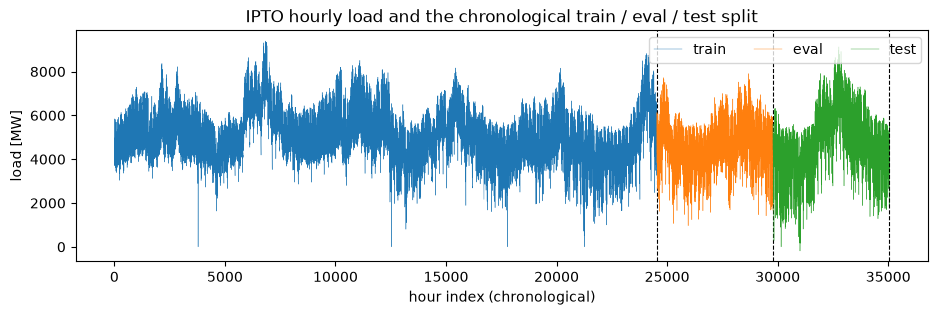

In [4]:
fig, ax = plt.subplots(figsize=(11, 3))
offset = 0
for split, color in (("train", "tab:blue"), ("eval", "tab:orange"), ("test", "tab:green")):
    y = data.denormalize(split, data.targets[split])
    ax.plot(np.arange(offset, offset + y.size), y, lw=0.3, color=color, label=split)
    offset += y.size
    ax.axvline(offset, color="k", lw=0.8, ls="--")
ax.set_xlabel("hour index (chronological)"); ax.set_ylabel("load [MW]"); ax.set_title("IPTO hourly load and the chronological train / eval / test split")
ax.legend(loc="upper right", ncol=3); plt.show()

## 3. The method in a few equations

**Quantum neuron** (Fig. 2).
- *Inputs:* each neuron reads 4 angles: $4-k_i$ input lags plus $k_i\in\{0,1,2\}$ outputs of other neurons (random wiring).
- *Encoding:* the angles are encoded as $R_X(x_q)$ on 4 qubits.
- *Ansatz:* two blocks of $R_X(w_q)$, followed by a $CX$–$R_Z(w_{q-1}-w_q)$–$CX$ ladder. The weights $w$ are random and **fixed** (reservoir computing).
- *Output:* $\langle Z^{\otimes 4}\rangle\in[-1,1]$.

The network is updated synchronously 3 times, and the outputs after the last pass are the features $r(t)\in\mathbb{R}^N$.

**Implementation detail:** because the weights are fixed, the whole ansatz plus measurement is a fixed 16×16 matrix $M$ with $\langle O\rangle=\mathrm{Tr}(M\rho_{\rm in})$. This makes simulation cheap (`lib/quantum_neuron.py`).

**Fidelity kernel** (Fig. 3). The feature map applies 2 blocks of $L=\lceil d/n\rceil$ layers of $[H, P(2x_i)]$ on $n=5$ or $10$ qubits. It has **no entangling gate**, so the state is a product state and the kernel factorizes exactly:

$$K(x,x') = \prod_{q=1}^{n} \frac{1 + \mathbf b_q(x)\cdot \mathbf b_q(x')}{2},$$

where $\mathbf b_q$ is the Bloch vector of qubit $q$.

> This is the single most important observation of the reproduction. The paper's "quantum ridge" is a classically computable kernel, in closed form, with cost $O(nd)$ per pair. This is what we compute (`lib/kernels.py`). Section 4 checks it against an independent quantum simulation.

**Readouts:**
- *Linear ridge:* $\hat y = W r + b$.
- *Kernel ridge:* $\hat y(x) = \sum_j \alpha_j K(x, x_j)$, with $(K + n\lambda I)\alpha = y$ on the full training set ($n = 24{,}535$, solved by Cholesky).

**Distributed readouts** split $r(t)$ into contiguous chunks, fit one readout per chunk, and average the predictions.

## 4. Known-answer sanity checks

Before trusting any number, we check the two quantum components against an **independent** simulator, Qiskit. Our simulation must agree with it to numerical precision.

In [5]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

def qiskit_neuron(x, w):
    # Fig. 2, gate for gate: RX encoding, then 2 blocks of RX(w) and a CX-RZ-CX ladder.
    qc = QuantumCircuit(4)
    for q in range(4): qc.rx(x[q], q)
    for _ in range(2):
        for q in range(4): qc.rx(w[q], q)
        for t in range(1, 4):
            qc.cx(t - 1, t); qc.rz(w[t - 1] - w[t], t); qc.cx(t - 1, t)
    return qc

def qiskit_feature_map(x, n):
    # Fig. 3: 2 blocks of L layers of [H, P(2x)].
    L = int(np.ceil(len(x) / n)); pad = np.zeros(L * n); pad[: len(x)] = x
    qc = QuantumCircuit(n)
    for _ in range(2):
        for layer in range(L):
            for q in range(n): qc.h(q); qc.p(2 * pad[layer * n + q], q)
    return qc

rng = np.random.default_rng(0)
neuron_err, kernel_err = [], []
for _ in range(20):
    x, w = rng.uniform(-1, 1, 4), rng.uniform(0, 2 * np.pi, 4)
    ours = neuron_expectations(neuron_functional(w, IDEAL, "z_all")[None], x[None, None, :])[0, 0]
    ref = Statevector(qiskit_neuron(x, w)).expectation_value(SparsePauliOp("ZZZZ")).real
    neuron_err.append(abs(ours - ref))
    xa, xb = rng.uniform(-1, 1, (2, 20))
    ours_k = float(kernel_block(torch.from_numpy(bloch_vectors(xa[None], 10)), torch.from_numpy(bloch_vectors(xb[None], 10)), 1.0)[0, 0])
    ref_k = abs(Statevector(qiskit_feature_map(xa, 10)).inner(Statevector(qiskit_feature_map(xb, 10)))) ** 2
    kernel_err.append(abs(ours_k - ref_k))
print(f"quantum neuron  vs Qiskit statevector: max |error| = {max(neuron_err):.1e}  (20 random neurons)")
print(f"closed-form kernel vs Qiskit fidelity : max |error| = {max(kernel_err):.1e}  (20 random pairs, 20 features, 10 qubits)")
assert max(neuron_err) < 1e-10 and max(kernel_err) < 1e-10

quantum neuron  vs Qiskit statevector: max |error| = 3.9e-16  (20 random neurons)
closed-form kernel vs Qiskit fidelity : max |error| = 6.0e-17  (20 random pairs, 20 features, 10 qubits)


**Observation:** both components match Qiskit to about $10^{-15}$. The noisy versions are also checked against Qiskit Aer in `tests/`, which hold 48 tests in total.

**Inference:**
- The reproduction implements the circuits the paper draws.
- The "quantum ridge" is *numerically identical* to a classical closed-form kernel. On this paper, the control "B2a: the same kernel evaluated classically" of our fair-baseline plan is therefore not a separate experiment: it is the same computation.

**Remaining uncertainty:** the drawings leave some choices open: the observable qubits, the wiring and the update order. We tested the open ones as declared variants (Section 10).

**Claim impact:** this does not yet affect C1, but it reframes C2. Any advantage of the kernel readout is an advantage of a kernel choice, not of a quantum device.

## 5. Pipeline walkthrough on one configuration

One configuration (SRSR, 10 neurons, seed 0), step by step, with the same functions the runner uses:

1. The window is passed to the reservoir, which produces features.
2. A readout is fitted on train, with λ chosen on eval.
3. The readout predicts on test.

In [6]:
from distributed_qrc.lib.architectures import build_cell_spec
from distributed_qrc.lib.readouts import fit_kernel_ridge, fit_linear_ridge

spec = build_cell_spec("srsr", 10)
cfg0 = load_paper_config(); cfg0["seed"] = 0
features = runner._reservoir_features(cfg0, data, spec, 0, "quantum_ideal", ["ibm_brisbane"])
print("quantum reservoir features:", {s: v.shape for s, v in features.items()}, "| range", float(features["train"].min()), float(features["train"].max()))

lin = fit_linear_ridge(features, data.targets, cfg0["readout"]["lambda_grid"])
# Reduced kernel fit for the live walkthrough (2,000 selection / 4,000 fit points); the stored results use all 24,535.
ker = fit_kernel_ridge(features, data.targets, cfg0["readout"]["lambda_grid"], n_qubits=10, noise=IDEAL, device="cpu",
                       selection_subsample=2000, fit_subsample=4000)
for name, fit in (("linear ridge", lin), ("kernel ridge (reduced fit)", ker)):
    err = data.targets["test"] - fit.predictions["test"]
    print(f"{name:28s} λ*={fit.lambda_selected:.0e}  test MAE={np.abs(err).mean():.4f}  test MAE [MW]={np.abs(data.denormalize('test', data.targets['test']) - data.denormalize('test', fit.predictions['test'])).mean():.0f}")

quantum reservoir features: {'train': (24535, 10), 'eval': (5254, 10), 'test': (5263, 10)} | range -0.3048967071395171 0.9462048522633588


linear ridge                 λ*=1e-07  test MAE=0.0164  test MAE [MW]=154
kernel ridge (reduced fit)   λ*=1e-08  test MAE=0.0142  test MAE [MW]=133


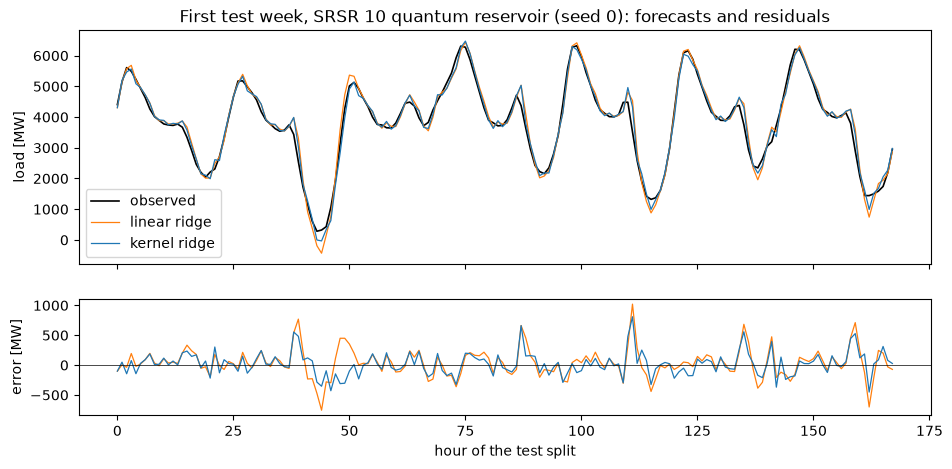

In [7]:
hours = slice(0, 24 * 7)
y = data.denormalize("test", data.targets["test"])[hours]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
a1.plot(y, color="k", lw=1.2, label="observed")
for name, fit, c in (("linear ridge", lin, "tab:orange"), ("kernel ridge", ker, COLORS["quantum"])):
    p = data.denormalize("test", fit.predictions["test"])[hours]
    a1.plot(p, lw=0.9, color=c, label=name); a2.plot(p - y, lw=0.9, color=c)
a1.set_ylabel("load [MW]"); a1.legend(); a1.set_title("First test week, SRSR 10 quantum reservoir (seed 0): forecasts and residuals")
a2.axhline(0, color="k", lw=0.5); a2.set_ylabel("error [MW]"); a2.set_xlabel("hour of the test split"); plt.show()

## 6. A small live experiment (reduced; 3 seeds)

We run the actual runner on **SRSR 10** for seeds 0–2, with a reduced kernel budget: 1,000 selection points and 3,000 fit points instead of 8,000 and 24,535. The run compares the paper's cells with two reservoir-free classical floors:

| Reservoir | Readouts |
|---|---|
| `classical` (paper baseline reservoir, ReservoirPy defaults) | linear, product kernel, RBF kernel |
| `quantum_ideal` | linear, product kernel, RBF kernel |
| `raw_lags`: **no reservoir**, the readout sees the 4 lags | linear (= AR(4)), product kernel, RBF kernel |

`product kernel` is the paper's "quantum ridge", evaluated in closed form. The RBF kernel is a standard classical kernel, with γ chosen on eval.

**Reduction disclosed:** the kernels see at most 3,000 training points, so absolute values are slightly worse than the stored full runs. Section 7 shows the full-data results; this live run only demonstrates the pipeline and the *ordering* of the models.

In [8]:
live_cfg = load_paper_config()
live_cfg["experiment"].update(id="NOTEBOOK-LIVE", variant="notebook", architecture="srsr", sizes=[10],
                              reservoir_types=["classical", "quantum_ideal", "raw_lags"],
                              readout_types=["linear", "quantum_kernel_ideal", "rbf_kernel"])
live_cfg["readout"].update(kernel_selection_subsample=1000, kernel_fit_subsample=3000)
live_cfg["logging"]["level"] = "warning"

live_rows, t0 = [], time.perf_counter()
with tempfile.TemporaryDirectory() as tmp:
    for seed in (0, 1, 2):
        cfg_s = copy.deepcopy(live_cfg); cfg_s["seed"] = seed
        run_dir = Path(tmp) / f"seed{seed}"; run_dir.mkdir()
        runner.train_and_evaluate(cfg_s, run_dir)
        for c in json.loads((run_dir / "metrics.json").read_text())["cells"]:
            live_rows.append({"seed": seed, "reservoir": c["reservoir_type"], "readout": c["readout_type"],
                              "eval RMSE": c["metrics"]["eval"]["rmse"], "test MAE": c["metrics"]["test"]["mae"]})
persistence = fit_persistence(data.inputs, data.targets)
print(f"live run: 3 seeds x 9 cells in {time.perf_counter() - t0:.0f} s; persistence test MAE = {np.abs(data.targets['test'] - persistence.predictions['test']).mean():.4f}")
live = pd.DataFrame(live_rows)
table = live.pivot_table(index=["reservoir", "readout"], columns="seed", values="test MAE")
table["mean"], table["std"] = table.mean(axis=1), table[[0, 1, 2]].std(axis=1)
display(table.sort_values("mean").style.format("{:.4f}"))

live run: 3 seeds x 9 cells in 23 s; persistence test MAE = 0.0339


**Observation:**
- **The paper's baseline reservoir is unstable.** The default ReservoirPy reservoir (`classical`) gives large, seed-dependent errors whatever the readout: 0.015–0.060.
- **With its linear readout it even loses to a plain AR(4)** on the raw lags (0.0163), in all 3 seeds.
- **The other models are close together.** On the quantum features and on the raw lags, every model lands in a narrow band. The kernel readouts sit at 0.0144–0.0147 and the linear ones at about 0.0165.
- **The reservoir-free product kernel** on the raw lags (0.0144) is at least as good as quantum reservoir + quantum kernel (0.0147).

**Inference:**
- The large "quantum" gain over the paper's baseline comes mostly from a weak baseline reservoir. Then, a smaller part comes from the move from a linear to a kernel readout (0.0165 → 0.0145).
- The quantum reservoir adds nothing measurable on top of a kernel applied to the raw window.

**Remaining uncertainty:** this is a reduced, single-configuration run. Sections 7–9 test the same pattern at full scale, on all 32 configurations.

**Claim impact:** this live run already suggests that C1 may be a baseline effect. It is not yet decisive.

## 7. Headline reproduction (stored full runs)

**Source:**
- the sweeps `E1-R2 … E4-R2`: 4 architectures × 8 configurations × 9 cells, seeds 0–2, full training set for every kernel;
- run on a laptop CPU (E1, E2) and on NVIDIA L4 GPUs (E3, E4);
- code pinned by `lib_sha256 19c36e44…`; logs validated and audited (`LOG.md`, *R2*).

The tables were aggregated from the raw `metrics.json` files by `utils/compare_with_paper.py` and `utils/headline_statistics.py`.

### 7a. Per-cell agreement with the paper (metric reproduction)

In [9]:
rows = []
for arch, exp in ARCHS.items():
    df = pd.read_csv(RESULTS / f"{exp}-R2_vs_paper.csv")
    for cell in ["quantum_ideal|quantum_kernel_ideal", "classical|quantum_kernel_ideal", "quantum_ideal|linear", "classical|linear", "quantum_noisy|quantum_kernel_noisy"]:
        g = df[(df.reservoir + "|" + df.readout) == cell]
        rows.append({"architecture": arch.upper(), "cell": cell, "configs within 12 %": f"{int((g.mae_rel.abs() <= 0.12).sum())}/8",
                     "median rel. Δ MAE": g.mae_rel.median(), "ours (mean MAE)": g.mae_ours.mean(), "paper (mean MAE)": g.mae_paper.mean()})
cell_table = pd.DataFrame(rows)
display(cell_table.style.format({"median rel. Δ MAE": "{:+.0%}", "ours (mean MAE)": "{:.4f}", "paper (mean MAE)": "{:.4f}"}).hide(axis="index"))

architecture,cell,configs within 12 %,median rel. Δ MAE,ours (mean MAE),paper (mean MAE)
SRSR,quantum_ideal|quantum_kernel_ideal,8/8,-2%,0.0139,0.0141
SRSR,classical|quantum_kernel_ideal,3/8,-8%,0.0166,0.0191
SRSR,quantum_ideal|linear,1/8,-15%,0.0153,0.0184
SRSR,classical|linear,5/8,+3%,0.0200,0.0237
SRSR,quantum_noisy|quantum_kernel_noisy,0/8,-27%,0.0140,0.0195
MRSR,quantum_ideal|quantum_kernel_ideal,8/8,-2%,0.0139,0.0141
MRSR,classical|quantum_kernel_ideal,4/8,+3%,0.0164,0.0170
MRSR,quantum_ideal|linear,3/8,-13%,0.0155,0.0180
MRSR,classical|linear,3/8,+13%,0.0203,0.0200
MRSR,quantum_noisy|quantum_kernel_noisy,3/8,-16%,0.0140,0.0172


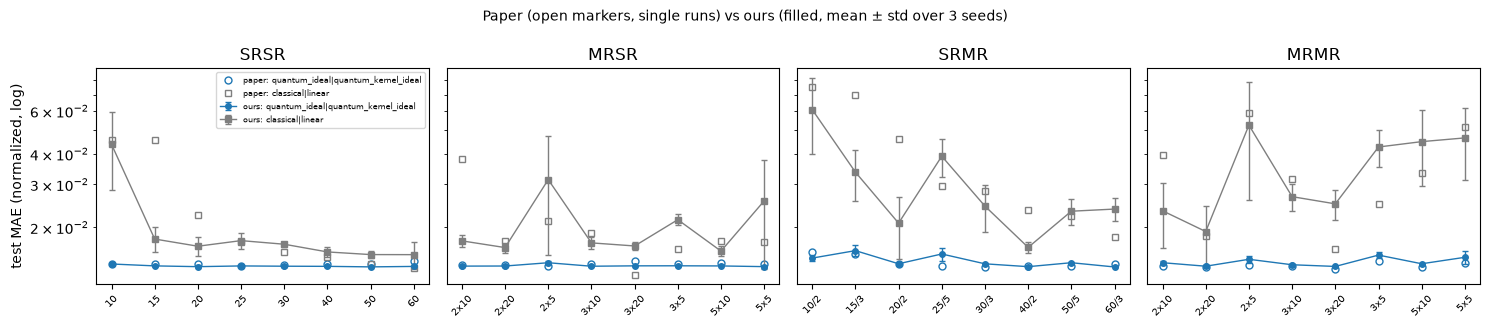

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
for ax, (arch, exp) in zip(axes, ARCHS.items()):
    df = pd.read_csv(RESULTS / f"{exp}-R2_vs_paper.csv")
    for cell, c, m in (("quantum_ideal|quantum_kernel_ideal", COLORS["quantum"], "o"), ("classical|linear", COLORS["b0"], "s")):
        g = df[(df.reservoir + "|" + df.readout) == cell]
        x = np.arange(len(g))
        ax.errorbar(x, g.mae_ours, yerr=g.mae_ours_std, color=c, marker=m, ms=4, lw=1, capsize=2, label=f"ours: {cell}")
        ax.plot(x, g.mae_paper, color=c, marker=m, ms=5, lw=0, mfc="none", label=f"paper: {cell}")
    ax.set_xticks(x, g.configuration, rotation=45, fontsize=7); ax.set_yscale("log"); ax.set_title(arch.upper())
axes[0].set_ylabel("test MAE (normalized, log)"); axes[0].legend(fontsize=6)
fig.suptitle("Paper (open markers, single runs) vs ours (filled, mean ± std over 3 seeds)", fontsize=10); plt.tight_layout(); plt.show()

**Observation:**
- The fully quantum ideal cell reproduces within 12 % in **32/32 configurations**.
- The paper's baseline (`classical|linear`, gray) is much noisier. The paper's values often fall at one extreme of our seed spread.
- Noisy cells do not degrade as much as in the paper. See the limitations in Section 12.

**Inference:** the quantum models are implemented as described. The baseline is the unstable element.

**Remaining uncertainty:** the paper's linear readouts on quantum features are 10–49 % worse than ours. The cause is unresolved: the missing intercept was tested and rejected.

### 7b. Headline reductions (C1 as the paper computes it)

The paper's headline is the reduction of the best quantum/hybrid cell vs the classical baseline, averaged over the 8 configurations. We recompute it with the paper's rule (best *test* R², which uses the test set for selection) and with eval selection.

In [11]:
head = read_json("headline_statistics.json")
rows = []
for arch in ARCHS:
    p, o = head["paper"][arch]["mae"], head["ours"][arch]
    pr, ev = o["paper_rule"]["mae"], o["eval_selected"]["mae"]
    rows.append({"architecture": arch.upper(), "paper avg": p["average"], "ours avg (paper rule)": pr["average_mean"], "± std": pr["average_std"],
                 "per-seed avg": ", ".join(f"{s['average']:.0%}" for s in pr["per_seed"]), "ours avg (eval-selected)": ev["average_mean"],
                 "paper peak": p["peak"], "ours peak (paper rule)": pr["peak_mean"]})
df = pd.DataFrame(rows)
display(df.style.format({c: "{:.1%}" for c in df.columns if c not in ("architecture", "per-seed avg")}).hide(axis="index"))

architecture,paper avg,ours avg (paper rule),± std,per-seed avg,ours avg (eval-selected),paper peak,ours peak (paper rule)
SRSR,28.5%,23.4%,1.5%,"25%, 23%, 23%",22.6%,69.2%,64.9%
MRSR,24.7%,26.2%,3.6%,"27%, 30%, 22%",24.5%,63.4%,57.9%
SRMR,54.2%,44.1%,3.1%,"46%, 46%, 41%",43.8%,78.8%,75.5%
MRMR,52.1%,51.8%,5.9%,"50%, 59%, 47%",51.6%,76.1%,75.4%


**Observation:**
- Against the paper's baseline, our reductions are of the same size as the paper's: 23–52 % on average, 58–76 % at peak.
- Selecting the best cell on eval instead of test lowers the averages by 0.2–1.7 points and leaves the peaks unchanged.

**Inference:** the headline is *quantitatively close to the paper* for MRSR and MRMR and *the same in trend* for SRSR and SRMR. The test-set selection in the paper is not what produces it.

**Claim impact:** the **C1 numbers reproduce against the paper's own baseline**. Whether that baseline is a fair reference is the question of Section 8.

## 8. Fair baseline comparison (stored full runs)

**Source:**
- sweeps `E{1..4}-CLASSICAL`, `B1B3-RAW` and `C6-*`: 33 runs, seeds 0–2, full data, code `lib_sha256 086ec349…`;
- rules frozen in `LOG.md#Phase 5 Comparison Plan` *before* any run;
- aggregated by `utils/fair_comparison.py` into `results/fair_comparison.json`.

**Baselines (independent controls, not part of the paper):**

| ID | Model | Why it is a credible competitor |
|---|---|---|
| B0 | ReservoirPy defaults + linear ridge | the paper's own baseline |
| B1 | persistence; AR(4) linear ridge on the raw window | the floors: is a reservoir needed at all? |
| B2b | RBF kernel ridge on the **same** reservoir features | the same readout *type* as the quantum kernel |
| B3 | product kernel and RBF kernel on the raw 4 lags | is the reservoir needed when the readout is a kernel? |
| B4 | ESN tuned on eval (12 settings), linear and RBF readouts | a tuned classical reservoir |

**What is matched, and what is not:**

| Dimension | Status | Comment |
|---|---|---|
| Information and inputs | **matched** | the same 4-lag windows, splits and normalization for all models |
| Reservoir size | **matched** for B0, B2b and B4 | same total neurons, sub-reservoirs and readout instances. B1/B3 use **fewer** resources (no reservoir) |
| Parameter count | **matched** for kernel readouts | kernel ridge always has $n = 24{,}535$ dual coefficients. Linear readouts have $N+1$ weights. The reservoir weights are fixed in every model, and the quantum neurons have $4N$ fixed angles |
| Training data | **matched** | the full training split for every final fit, and the same 8,000-point subsample for every kernel selection |
| Optimization | **matched** | closed-form ridge everywhere; no iterative training |
| Tuning budget | **not matched**: the classical side gets *more* | quantum cells tune λ (10 values); RBF tunes γ×λ (50); B4 tunes 12 ESN settings × λ, then γ×λ. Disclosed as an asymmetry |
| Compute and wall time | not matched, reported | about 50 s per product-kernel fit and 80 s per RBF fit on a laptop CPU (Section 10) |
| Evaluation protocol | **matched** | eval selection on both sides, test reported once, 3 seeds |

In [12]:
fair = read_json("fair_comparison.json")
rows = []
for arch in ARCHS:
    a = fair["architectures"][arch]
    for config, sel in a["eval_selected"].items():
        q, c, m = (sel[k]["picks"] for k in ("quantum", "fair_classical", "merlin"))
        rows.append({"arch": arch.upper(), "config": config,
                     "quantum (eval-sel.)": np.mean([p["test_mae"] for p in q]), "q seeds": " ".join(f"{p['test_mae']:.4f}" for p in q),
                     "fair classical (eval-sel.)": np.mean([p["test_mae"] for p in c]), "c seeds": " ".join(f"{p['test_mae']:.4f}" for p in c),
                     "classical cell(s)": ", ".join(sorted({p["cell"] for p in c})),
                     "paper baseline B0": a["per_configuration"][config]["classical|linear"]["mean"],
                     "verdict": a["claims"]["C1_vs_fair_classical"]["configurations"][config]["verdict"]})
fair_table = pd.DataFrame(rows)
display(fair_table.style.format({"quantum (eval-sel.)": "{:.4f}", "fair classical (eval-sel.)": "{:.4f}", "paper baseline B0": "{:.4f}"}).hide(axis="index"))

arch,config,quantum (eval-sel.),q seeds,fair classical (eval-sel.),c seeds,classical cell(s),paper baseline B0,verdict
SRSR,10,0.0141,0.0140 0.0141 0.0143,0.0138,0.0138 0.0138 0.0138,raw_lags|quantum_kernel_ideal,0.0438,worse
SRSR,20,0.0135,0.0126 0.0143 0.0135,0.0137,0.0131 0.0144 0.0136,classical|rbf_kernel,0.0167,tie
SRSR,40,0.0136,0.0132 0.0133 0.0143,0.0123,0.0118 0.0121 0.0130,"classical|rbf_kernel, esn_tuned|rbf_kernel",0.0159,worse
SRSR,15,0.0140,0.0141 0.0139 0.0139,0.0138,0.0140 0.0138 0.0135,"classical|rbf_kernel, raw_lags|quantum_kernel_ideal",0.0179,tie
SRSR,30,0.0141,0.0144 0.0139 0.0139,0.0135,0.0146 0.0134 0.0126,"classical|rbf_kernel, esn_tuned|rbf_kernel",0.0171,tie
SRSR,60,0.0130,0.0140 0.0117 0.0133,0.0129,0.0139 0.0117 0.0130,classical|rbf_kernel,0.0155,tie
SRSR,25,0.0148,0.0149 0.0150 0.0145,0.0145,0.0143 0.0148 0.0144,classical|rbf_kernel,0.0176,tie
SRSR,50,0.0135,0.0131 0.0140 0.0135,0.0129,0.0128 0.0126 0.0133,classical|rbf_kernel,0.0155,tie
MRSR,2x5,0.0144,0.0143 0.0146 0.0142,0.0138,0.0138 0.0138 0.0138,raw_lags|quantum_kernel_ideal,0.0314,worse
MRSR,2x10,0.0139,0.0139 0.0138 0.0141,0.0140,0.0138 0.0138 0.0145,"classical|rbf_kernel, raw_lags|quantum_kernel_ideal",0.0176,tie


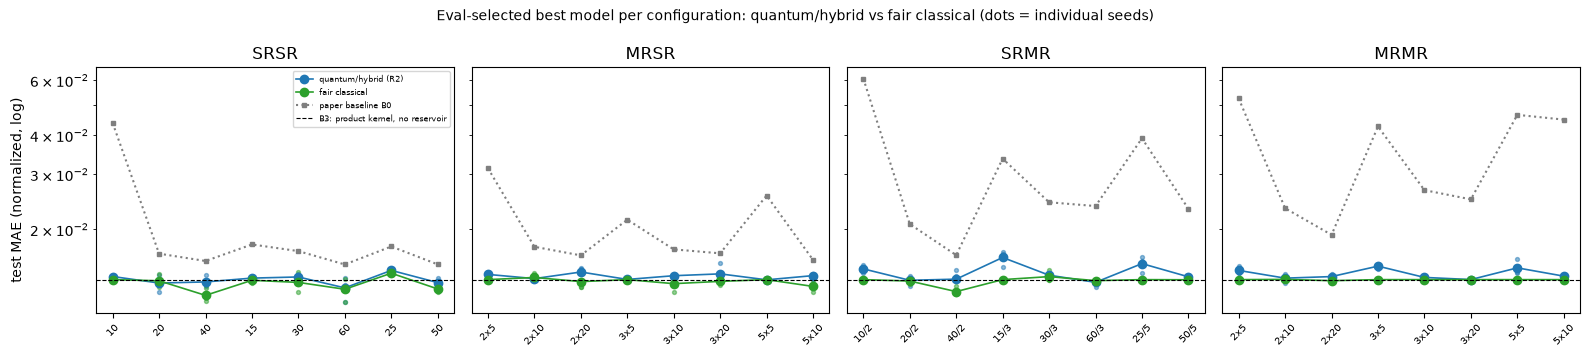

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, arch in zip(axes, ARCHS):
    sub = fair_table[fair_table.arch == arch.upper()]
    x = np.arange(len(sub))
    for col, seeds, color, label in (("quantum (eval-sel.)", "q seeds", COLORS["quantum"], "quantum/hybrid (R2)"), ("fair classical (eval-sel.)", "c seeds", COLORS["classical"], "fair classical")):
        ax.plot(x, sub[col], color=color, marker="o", lw=1.2, label=label)
        for i, s in enumerate(sub[seeds]):  # individual seeds
            ax.scatter([i] * 3, [float(v) for v in s.split()], color=color, s=8, alpha=0.5)
    ax.plot(x, sub["paper baseline B0"], color=COLORS["b0"], ls=":", marker="s", ms=3, label="paper baseline B0")
    ax.axhline(fair["architectures"][arch]["per_configuration"][sub.config.iloc[0]]["raw_lags|quantum_kernel_ideal"]["mean"], color="k", ls="--", lw=0.8, label="B3: product kernel, no reservoir")
    ax.set_xticks(x, sub.config, rotation=45, fontsize=7); ax.set_yscale("log"); ax.set_title(arch.upper())
axes[0].set_ylabel("test MAE (normalized, log)"); axes[0].legend(fontsize=6)
fig.suptitle("Eval-selected best model per configuration: quantum/hybrid vs fair classical (dots = individual seeds)", fontsize=10); plt.tight_layout(); plt.show()

In [14]:
rows = []
for arch in ARCHS:
    a = fair["architectures"][arch]
    c1, b0 = a["claims"]["C1_vs_fair_classical"], a["claims"]["C1_vs_paper_baseline_B0"]
    h = a["E7_headline_vs_fair_classical"]["mae"]
    dm = [r for r in a["diebold_mariano"]["rows"] if r["loss"] == "abs" and r["lag"] == 24]
    rows.append({"architecture": arch.upper(), "vs fair classical: better / tie / worse": f"{c1['counts']['better']} / {c1['counts']['tie']} / {c1['counts']['worse']}",
                 "C1 vs fair": c1["outcome"], "vs paper B0: better": f"{b0['counts']['better']}/8",
                 "avg MAE reduction vs fair": f"{h['average']['mean']:+.1%} ± {h['average']['std']:.1%}",
                 f"DM at headline config (seeds 0,1,2)": " ".join(f"{r['dm']:+.1f}" for r in dm)})
display(pd.DataFrame(rows).style.hide(axis="index"))

architecture,vs fair classical: better / tie / worse,C1 vs fair,vs paper B0: better,avg MAE reduction vs fair,"DM at headline config (seeds 0,1,2)"
SRSR,0 / 6 / 2,UNSUPPORTED,7/8,-3.1% ± 1.0%,+2.4 +3.8 +3.1
MRSR,0 / 6 / 2,UNSUPPORTED,6/8,-3.9% ± 1.9%,+4.3 +1.6 +0.7
SRMR,0 / 5 / 3,UNSUPPORTED,7/8,-6.3% ± 1.9%,+8.8 +5.7 +9.2
MRMR,0 / 4 / 4,UNSUPPORTED,5/8,-4.4% ± 1.5%,+6.7 +9.0 +7.9


The decision rule was fixed before the runs: model A is "better" than B in a configuration if $\overline{\rm MAE}_A - \overline{\rm MAE}_B < -2\sigma_{\rm pooled}$ over the 3 seeds. The Diebold-Mariano statistic is computed on the test errors (HLN correction, lag 24); a positive value means the quantum model has the larger loss.

**Observation:**
- Against fair classical models, the eval-selected quantum/hybrid model is **better in 0/8 configurations in every architecture**. It ties in 4–6/8 and is worse in the rest.
- The average "reduction" turns negative, −3 % to −6 %.
- Diebold-Mariano tests favour the classical model in 10 of 12 seed-level tests, and favour the quantum model in none.
- The classical winner is very often **B3, the paper's own product kernel on the raw lags with no reservoir**.

**Inference:** the paper's gains are explained by its weak baseline: default, untuned ReservoirPy features with a *linear* readout, which at small sizes is worse than a plain AR(4). Once the classical side may use a kernel too, or simply drops the reservoir, nothing quantum remains.

**Remaining uncertainty:** the frozen RBF γ grid and ESN grid were often selected at their edges. A wider grid could only improve the classical side, so this limits the comparison in the quantum models' favour.

**Claim impact:** **C1 is not supported** against fair classical baselines. It is only supported against the paper's mismatched baseline.

## 9. Controls that separate the paper's explanations from alternatives

| Control | Paper's explanation | Alternative explanation | Decisive comparison |
|---|---|---|---|
| Kernel swap on **identical** features (C2) | the *quantum* kernel is what helps | any good nonlinear kernel helps | product kernel vs RBF on the same features |
| Reservoir removal (B3) | the quantum *reservoir* creates useful features | the window plus a kernel is enough | kernel on raw lags vs quantum reservoir + kernel |
| Same-device noise (C6) | distribution mitigates noise | the paper put the single-reservoir model on the noisiest device | MRSR vs SRSR at ×10 noise, paper mapping vs one device for all |
| Best cell (C7) | the 3×20 hybrid is the best model | it is a kernel model like the others | hybrid vs fair classical at 3×20 |

In [15]:
rows = []
for arch in ARCHS:
    a = fair["architectures"][arch]
    for key, label in (("C2_quantum_features", "quantum features: product vs RBF"), ("C2_classical_features", "B0 features: product vs RBF")):
        c = a["claims"][key]["counts"]
        rows.append({"architecture": arch.upper(), "comparison": label, "product kernel better / tie / worse": f"{c['better']} / {c['tie']} / {c['worse']}", "outcome": a["claims"][key]["outcome"]})
display(pd.DataFrame(rows).style.hide(axis="index"))
c7 = fair["C7"]
print(f"C7: MRSR 3x20 hybrid {c7['hybrid_3x20']['mean']:.5f} ± {c7['hybrid_3x20']['std']:.5f} vs fair classical {c7['fair_classical_3x20']['mean']:.5f} ± {c7['fair_classical_3x20']['std']:.5f} -> {c7['verdict']} (paper 0.0113)")

architecture,comparison,product kernel better / tie / worse,outcome
SRSR,quantum features: product vs RBF,7 / 1 / 0,SUPPORTED
SRSR,B0 features: product vs RBF,0 / 8 / 0,UNSUPPORTED
MRSR,quantum features: product vs RBF,7 / 1 / 0,SUPPORTED
MRSR,B0 features: product vs RBF,0 / 8 / 0,UNSUPPORTED
SRMR,quantum features: product vs RBF,4 / 4 / 0,PARTIALLY_SUPPORTED
SRMR,B0 features: product vs RBF,0 / 8 / 0,UNSUPPORTED
MRMR,quantum features: product vs RBF,2 / 6 / 0,UNSUPPORTED
MRMR,B0 features: product vs RBF,0 / 8 / 0,UNSUPPORTED


C7: MRSR 3x20 hybrid 0.01459 ± 0.00097 vs fair classical 0.01365 ± 0.00032 -> tie (paper 0.0113)


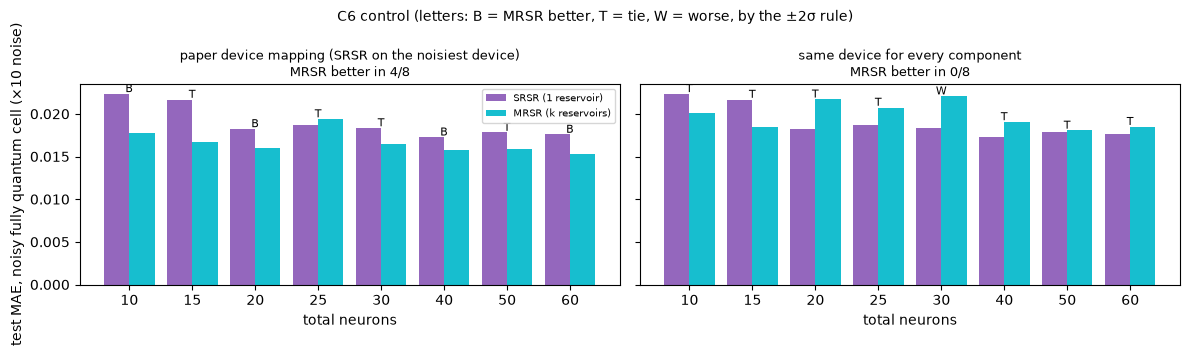

In [16]:
c6 = fair["C6_x10"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (mapping, title) in zip(axes, (("paper", "paper device mapping (SRSR on the noisiest device)"), ("ibm_brisbane", "same device for every component"))):
    rows = c6[mapping]["mrsr_vs_srsr"]["rows"]
    n = list(rows); x = np.arange(len(n))
    ax.bar(x - 0.2, [rows[k]["srsr"] for k in n], 0.4, label="SRSR (1 reservoir)", color="tab:purple")
    ax.bar(x + 0.2, [rows[k]["mrsr"] for k in n], 0.4, label="MRSR (k reservoirs)", color="tab:cyan")
    for i, k in enumerate(n):
        ax.text(x[i], max(rows[k]["srsr"], rows[k]["mrsr"]) * 1.01, rows[k]["verdict"][0].upper(), ha="center", fontsize=8)
    ax.set_xticks(x, n); ax.set_xlabel("total neurons"); ax.set_title(f"{title}\nMRSR better in {c6[mapping]['mrsr_vs_srsr']['better']}/8", fontsize=9)
axes[0].set_ylabel("test MAE, noisy fully quantum cell (×10 noise)"); axes[0].legend(fontsize=7)
fig.suptitle("C6 control (letters: B = MRSR better, T = tie, W = worse, by the ±2σ rule)", fontsize=10); plt.tight_layout(); plt.show()

**Observation:**
- **Kernel swap:** on the classical features, the paper's product kernel and an RBF kernel tie in 32/32 configurations. On the quantum features, the product kernel is better in SRSR and MRSR, but there the RBF γ was capped by its frozen grid.
- **Reservoir removal:** the product kernel on the raw lags (Section 8, dashed line) matches the best quantum model everywhere.
- **Same-device noise:** under the paper's device mapping, MRSR beats SRSR in 4/8 sizes. With the same device for every component, it beats SRSR in 0/8.
- **C7:** the hybrid ties with the fair classical models.

**Inference:**
- The kernel, not its quantum origin, explains the readout gain. It is a classical closed-form kernel in any case (Section 4).
- The apparent noise mitigation from distribution follows the device assignment, not the distribution.

**Remaining uncertainty:**
- Our noise model is rebuilt from the paper's calibration medians, and its strength had to be scaled ×10 to matter. The paper's own noise construction is unknown.
- A wider RBF grid could change the quantum-feature row of C2, but only against the quantum kernel.

**Claim impact:**
- **C2** and **C6** are not supported.
- **C7** is not supported: it is not reproduced (0.0146 vs 0.0113) and ties with the classical models.

## 10. Robustness and uncertainty

**Robustness checks** (sweeps `P1-ROBUST-R2`, `P1-R6R7-R2` and `GAP-*-R2`, run with predeclared rules; verdicts in `results/r2_verdicts.json`):

In [17]:
verdicts = read_json("r2_verdicts.json")
rows = []
for cand, v in verdicts["S2-R2"].items():
    rows.append({"check": f"S2 robustness {cand}", "result": f"headline Δ {v['headline_delta']:+.3f} (unchanged: {v['headline_unchanged']}); cells moved beyond 1 std: {sum(x['material'] for x in v['cells'].values())}/{len(v['cells'])}"})
rows.append({"check": "S5 missing-intercept hypothesis (linear cells)", "result": f"{verdicts['S5-R2']['cells_within_seed_std']}/{verdicts['S5-R2']['cells']} cells explained -> {verdicts['S5-R2']['intercept_hypothesis']}"})
rows.append({"check": "S4 noise strength closest to the paper's degradation", "result": f"{verdicts['S4-R2']['closest_scale']} (any scale fully consistent: {verdicts['S4-R2']['any_consistent']})"})
rows.append({"check": "S3 finite shots explain the noisy gap", "result": f"supported: {verdicts['S3-R2_H1_supported']} (shots over-degrade)"})
for arch, g in verdicts["GAP-CLASSICAL-R2"].items():
    rows.append({"check": f"B0 seed spread, {arch.upper()} (20 seeds)", "result": f"paper value inside our range in {g['inside']}/{g['configurations']} configurations"})
display(pd.DataFrame(rows).style.hide(axis="index"))

check,result
"S2 robustness {""normalization"": ""per_split""}",headline Δ -0.003 (unchanged: True); cells moved beyond 1 std: 1/4
"S2 robustness {""artifact_handling"": ""interpolate""}",headline Δ +0.004 (unchanged: True); cells moved beyond 1 std: 2/4
S5 missing-intercept hypothesis (linear cells),3/24 cells explained -> rejected
S4 noise strength closest to the paper's degradation,"{""noise_scale"": 10} (any scale fully consistent: False)"
S3 finite shots explain the noisy gap,supported: False (shots over-degrade)
"B0 seed spread, SRSR (20 seeds)",paper value inside our range in 4/8 configurations
"B0 seed spread, MRSR (20 seeds)",paper value inside our range in 6/8 configurations
"B0 seed spread, SRMR (20 seeds)",paper value inside our range in 7/8 configurations
"B0 seed spread, MRMR (20 seeds)",paper value inside our range in 7/8 configurations


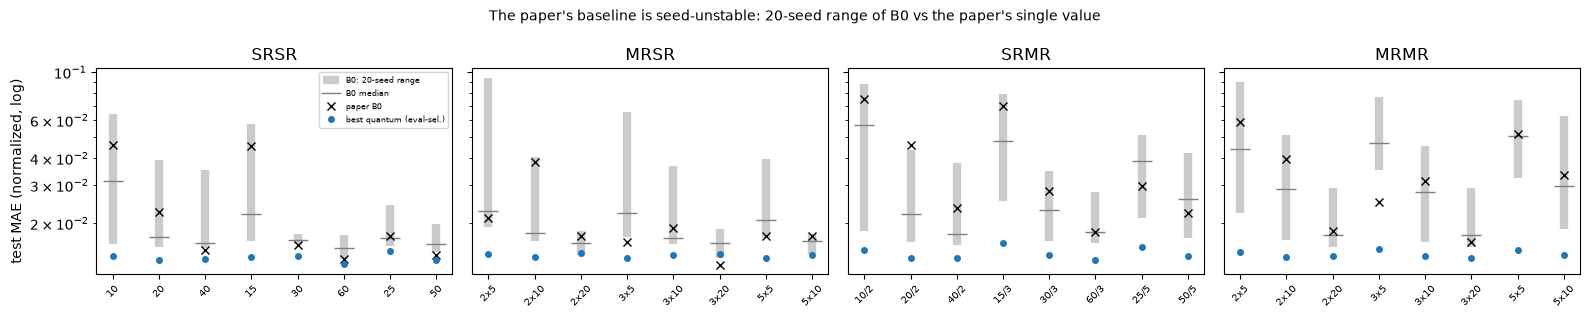

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, arch in zip(axes, ARCHS):
    spread = read_json(f"GAP-CLASSICAL-{arch.upper()}-R2_spread.json")["configurations"]
    n = list(spread); x = np.arange(len(n))
    ax.vlines(x, [spread[k]["min"] for k in n], [spread[k]["max"] for k in n], color=COLORS["b0"], lw=6, alpha=0.4, label="B0: 20-seed range")
    ax.plot(x, [spread[k]["median"] for k in n], "_", color=COLORS["b0"], ms=14, label="B0 median")
    ax.plot(x, [spread[k]["paper"] for k in n], "x", color=COLORS["paper"], label="paper B0")
    q = fair_table[fair_table.arch == arch.upper()]
    ax.plot(x, q["quantum (eval-sel.)"].values, "o", color=COLORS["quantum"], ms=4, label="best quantum (eval-sel.)")
    ax.set_xticks(x, n, rotation=45, fontsize=7); ax.set_yscale("log"); ax.set_title(arch.upper())
axes[0].set_ylabel("test MAE (normalized, log)"); axes[0].legend(fontsize=6)
fig.suptitle("The paper's baseline is seed-unstable: 20-seed range of B0 vs the paper's single value", fontsize=10); plt.tight_layout(); plt.show()

In [19]:
wall = fair["readout_seconds_per_cell"]
rows = [{"cell type": label, "laptop CPU (E1) [s]": wall[f"E1-{fam}|{cell}"]["mean"], "NVIDIA L4 (E4) [s]": wall[f"E4-{fam}|{cell}"]["mean"]}
        for label, fam, cell in (("product ('quantum') kernel ridge", "R2", "quantum_ideal|quantum_kernel_ideal"), ("RBF kernel ridge (50 γ×λ)", "CLASSICAL", "quantum_ideal|rbf_kernel"),
                                 ("MerLin photonic kernel ridge", "MERLIN", "photonic|photonic_kernel"), ("linear ridge", "R2", "quantum_ideal|linear"))]
show(pd.DataFrame(rows), "{:.1f}")

cell type,laptop CPU (E1) [s],NVIDIA L4 (E4) [s]
product ('quantum') kernel ridge,51.0,71.1
RBF kernel ridge (50 γ×λ),81.6,118.3
MerLin photonic kernel ridge,43.7,61.6
linear ridge,0.0,0.0


**Observation:**
- The headline is insensitive to the normalization and artifact choices.
- The paper's baseline values usually fall inside our 20-seed range (24/32 configurations), often in its unfavourable tail.
- The kernel fits take under two minutes per cell on full data (wall-clock above).

**Inference:** the headline reductions reflect where a single baseline seed lands as much as any model property.

**Remaining uncertainty:**
- Three seeds per cell.
- The paper's noisy degradation (14–35 %) is matched by no single noise scale (S3, S4).
- The paper's linear cells on quantum features remain 10–49 % worse than ours.

## 11. Photonic assessment with MerLin (extension)

**Status: `PARTIAL_MERLIN_TRANSLATION`.**
- *Translated:* the ideal reservoir, the kernel readout and the distribution (C1–C4, C7).
- *Excluded:* the gate-hardware noise claims (C5, C6).

The adaptation keeps the role of each component, not its gates:

| Paper (qubits) | MerLin adaptation (photons) |
|---|---|
| 4-qubit neuron, $\langle Z^{\otimes4}\rangle$ | frozen 4-mode chip, 2 photons in $\lvert1,0,1,0\rangle$: random interferometer → phase encoding of the 4 inputs → random interferometer → threshold detection; output $\langle n_0\rangle-1\in[-1,1]$ |
| 5/10-qubit product-state fidelity kernel | 5/10-mode chip, 2 photons, 2 re-uploading blocks; kernel $\lvert\langle\psi(x')\vert\psi(x)\rangle\rvert^2$ from Fock amplitudes. Not factorizable, because of two-photon interference |
| wiring, 3 passes, readout partition, merge, λ protocol | unchanged |

**Known-answer check, live.** MerLin's `UNBUNCHED` expectation values are **post-selected** on collision-free (2-click) events. We verify this against an independent Perceval computation.

In [20]:
import itertools
import perceval as pcvl

def perceval_amplitude(u, s_in, s_out):
    backend = pcvl.BackendFactory.get_backend("SLOS"); backend.set_circuit(pcvl.Unitary(pcvl.Matrix(u)))
    backend.set_input_state(pcvl.BasicState(s_in)); return backend.prob_amplitude(pcvl.BasicState(s_out))

def circuit_unitary(circuit, values):
    params = sorted((p for p in circuit.get_parameters(all_params=True) if p.name.startswith("px")), key=lambda p: int(p.name[2:]))
    for p, v in zip(params, values): p.set_value(float(v))
    return np.array(circuit.compute_unitary(use_symbolic=False))

layer = build_neuron_layer(1.0, np.random.SeedSequence(5))
x = np.random.default_rng(1).uniform(-1, 1, (3, 4))
with torch.no_grad():
    merlin_out = layer(torch.from_numpy(x)).numpy()
outputs = [o for o in itertools.product(range(3), repeat=4) if sum(o) == 2]
err_post, err_raw = [], []
for row, xi in zip(merlin_out, x):
    u = circuit_unitary(layer.circuit, xi)
    probs = {o: abs(perceval_amplitude(u, [1, 0, 1, 0], list(o))) ** 2 for o in outputs}
    free = {o: p for o, p in probs.items() if max(o) <= 1}
    post = [sum(p * o[m] for o, p in free.items()) / sum(free.values()) for m in range(4)]
    raw = [sum(p * o[m] for o, p in probs.items()) for m in range(4)]
    err_post.append(np.abs(row - post).max()); err_raw.append(np.abs(row - raw).max())
print(f"MerLin UNBUNCHED <n_i> vs Perceval, post-selected on 2 clicks: max |error| = {max(err_post):.1e}")
print(f"MerLin UNBUNCHED <n_i> vs Perceval, no post-selection     : max |error| = {max(err_raw):.1e}  (so it IS post-selected)")

km = PhotonicKernelMap(n_features=10, n_modes=10, n_photons=2, scale=2.0, blocks=2, sequence=np.random.SeedSequence(3))
G = state_gram(km.states(np.random.default_rng(0).uniform(-1, 1, (50, 10)))).numpy()
print(f"photonic kernel: Fock dimension {km.states(np.zeros((1, 10))).shape[1]}, Gram symmetric {np.allclose(G, G.T)}, unit diagonal {np.allclose(np.diag(G), 1)}, min eigenvalue {np.linalg.eigvalsh(G).min():.1e}")

MerLin UNBUNCHED <n_i> vs Perceval, post-selected on 2 clicks: max |error| = 1.1e-16
MerLin UNBUNCHED <n_i> vs Perceval, no post-selection     : max |error| = 5.4e-02  (so it IS post-selected)
photonic kernel: Fock dimension 55, Gram symmetric True, unit diagonal True, min eigenvalue 4.5e-01


**Stored results.** Sweeps `E{1..4}-MERLIN`: full grids, seeds 0–2, code `lib_sha256 764ee0c7…`. Aggregated by `utils/merlin_comparison.py`.

The tolerance was declared before the runs: the adaptation *preserves* the gate-model behaviour in a configuration if $|\Delta|\le\max(10\,\%, 2\sigma_{\rm pooled})$, and overall if this holds in at least 6/8 configurations.

In [21]:
merlin = read_json("merlin_comparison.json")
rows = []
for arch in ARCHS:
    m = merlin[arch]
    rows.append({"architecture": arch.upper(),
                 "photonic+photonic kernel vs gate full-quantum": f"{m['a_full_quantum']['verdict']} ({m['a_full_quantum']['preserved_count']}/8, median {m['a_full_quantum']['median_relative_delta']:+.1%})",
                 "photonic reservoir + linear vs gate + linear": f"{m['c_reservoir_linear']['verdict']} ({m['c_reservoir_linear']['median_relative_delta']:+.1%})",
                 "headline vs B0 (MerLin / gate)": f"{m['d_headline']['merlin']['mae']['average_mean']:.1%} / {m['d_headline']['r2_ideal']['mae']['average_mean']:.1%}",
                 "MerLin vs fair classical: better": f"{fair['architectures'][arch]['claims']['MERLIN_vs_fair_classical']['counts']['better']}/8"})
display(pd.DataFrame(rows).style.hide(axis="index"))
hw = pd.DataFrame([
    {"component": "neuron chip", "space": "UNBUNCHED", "detector": "threshold", "photons": 2, "modes": 4, "input": "[1,0,1,0]", "postselection": "yes (2-click)", "shots": "exact", "simulator": "MerLin 0.4.2"},
    {"component": "kernel chip", "space": "FOCK amplitudes", "detector": "threshold (compute-uncompute)", "photons": 2, "modes": "10 (5)", "input": "[1,0,0,0,0,1,0,0,0,0]", "postselection": "none", "shots": "exact", "simulator": "MerLin 0.4.2"}])
display(hw.style.hide(axis="index"))

architecture,photonic+photonic kernel vs gate full-quantum,photonic reservoir + linear vs gate + linear,headline vs B0 (MerLin / gate),MerLin vs fair classical: better
SRSR,"preserves (8/8, median +2.8%)",preserves (-3.1%),23.1% / 23.2%,0/8
MRSR,"preserves (8/8, median +2.5%)",preserves (-2.3%),25.1% / 26.1%,0/8
SRMR,"preserves (8/8, median +3.3%)",preserves (-1.1%),40.7% / 44.1%,0/8
MRMR,"preserves (8/8, median +3.0%)",preserves (-0.6%),46.8% / 51.8%,0/8


component,space,detector,photons,modes,input,postselection,shots,simulator
neuron chip,UNBUNCHED,threshold,2,4,"[1,0,1,0]",yes (2-click),exact,MerLin 0.4.2
kernel chip,FOCK amplitudes,threshold (compute-uncompute),2,10 (5),"[1,0,0,0,0,1,0,0,0,0]",none,exact,MerLin 0.4.2


**Observation:**
- The photonic adaptation preserves the gate-model behaviour in all four architectures. The photonic kernel is 2–3 % worse and the photonic reservoir slightly better.
- In small multi-readout configurations with 5-feature instances, the 2-photon, 5-mode kernel (15 amplitudes) is clearly weaker than the 5-qubit one (32 amplitudes).
- Against fair classical models, the MerLin cells are better in 0/32 configurations.

**Inference:** the method transfers to linear optics without loss, and without gain. A 2-photon kernel is classically simulable.

**Remaining uncertainty:**
- Simulation only: no losses, no distinguishability, and no shot cost.
- `merlin.FidelityKernel` could not be used. It deviated from the exact fidelity on these circuits (`ACTION_REQUIRED_SEND_TO_MERLIN_TEAM.md`).

**Extension verdict:** a faithful photonic translation, with no photonic advantage. A natural next use is a *distributed-stack* proof of concept (README, *Next Steps*). It is not an accuracy claim.

## 12. Conclusions

**Limitations of this reproduction** (all disclosed in the README and `LOG.md`):
- **Reductions:**
  - The live cells use reduced kernel fits (Sections 5 and 6). Every quantitative conclusion rests on the stored full runs instead (Sections 7–11).
  - 3 seeds per cell; 20 for the baseline spread.
- **Deviations:**
  - train-fitted normalization (per split tested in Section 10);
  - eval selection alongside the paper's test-selected rule;
  - noise model rebuilt from calibration medians, with exact expectations (no shots);
  - wiring, observable and merge rule inferred, with the open ones tested.
- **Not executed:** QPU or photonic hardware; the paper's exact noise construction; C8 (deployment, qualitative).
- **Supported only qualitatively:** the SRSR and SRMR headline averages (23 % vs 28.5 %, 44 % vs 54 %), which match in trend but not in value.

**Separating the outcomes:**

| Question | Answer | Evidence |
|---|---|---|
| Does the software execute? | yes: 48 tests and 196 audited sweep runs (139 R2, 24 MerLin, 33 phase 05) | §4, `tests/`, `LOG.md` |
| Does the method solve the task? | yes: test MAE ≈ 0.014, about 135 MW, R² ≈ 0.98, far better than persistence (0.034) | §5–7 |
| Does the paper's metric reproduce? | largely: the ideal cells within 12 % in 32/32 configurations; headline reductions vs its baseline of the same size; C7 not reproduced | §7 |
| Does the paper's explanation survive controls? | no: the gain comes from the kernel readout, which is classical; distribution has no noise effect under a same-device control | §4, §9 |
| Does the method beat a fair baseline? | no: better in 0/32 configurations; a reservoir-free classical kernel matches it | §8 |

**1. What reproduced:**
- the quantum models (§4);
- the ideal fully quantum cells (§7a);
- the headline reductions against the paper's own baseline (§7b);
- the observation that the kernel readout is the consistent contributor (§8–9).

**2. What did not reproduce:**
- the best overall model, C7 (§9);
- the size of the noisy degradation (§10);
- the paper's linear cells on quantum features (§7a).

**3. What remains unresolved:**
- the cause of the linear-cell gap;
- the paper's noise construction;
- whether wider classical tuning grids would also remove the C2 advantage on quantum features (§9).

**4. What was not attempted:**
- hardware execution;
- C8;
- a sweep of the distributed-readout merge rule. It was resolved from the paper's own tables instead.

**5. Reproduction verdict: partially reproduced.**
- The numbers reproduce against the paper's protocol.
- The comparative claims C1, C2, C5, C6 and C7 are **not supported** against fair, predeclared classical baselines.
- The decisive evidence: a classical closed-form kernel on the raw 4-hour window matches every quantum model (§8). No quantum advantage is shown.

**6. Extension verdict (MerLin):** a faithful, Perceval-verified photonic translation that preserves the behaviour of the gate model (§11), with no photonic advantage.

In [22]:
print(f"notebook executed in {time.perf_counter() - START:.0f} s on CPU")

notebook executed in 29 s on CPU
